# Aligning load and solar profiles with dynamic time warping

Align a detailed profile to a shorter reference with dynamic time warping (DTW). The path maintains chronological order while allowing one reference block to represent several observations. Use the number of assigned observations as an occurrence weight when dispatching the reduced profile in Energia.

The example uses two July 2019 days in Houston local time from the legacy Houston weather and ERCOT COAST load series. The source day has twelve two-hour blocks. The reference day has six four-hour blocks. The final comparison shows the effect of averaging on grid purchases.

## Align the two profiles

In [1]:
from math import isclose

import numpy as np
import pandas as pd
from energia import Model, Periods, Process, Resource
from gana import inf
from scipy.spatial.distance import cdist

# Each row has load (MW) and solar capacity factor.
detailed = np.array([
        [32.6711, 0.0],
        [31.2823, 0.0],
        [31.8884, 0.0],
        [33.2318, 0.001],
        [36.0509, 0.064],
        [40.4962, 0.2358],
        [43.1071, 0.0885],
        [44.1744, 0.2618],
        [44.8356, 0.0608],
        [42.8234, 0.0615],
        [40.6474, 0.0005],
        [37.0416, 0.0],
    ])
reference = np.array([
        [31.9925, 0.0],
        [32.2356, 0.0536],
        [39.6049, 0.5562],
        [46.9145, 0.3542],
        [44.4082, 0.2598],
        [38.6102, 0.0061],
    ])
scale = np.array([detailed[:, 0].max(), 1])
distance = cdist(detailed / scale, reference / scale, metric="cityblock")

cost = np.full((len(detailed) + 1, len(reference) + 1), np.inf)
cost[0, 0] = 0.0
for i in range(1, len(detailed) + 1):
    for j in range(1, len(reference) + 1):
        cost[i, j] = distance[i - 1, j - 1] + min(cost[i - 1, j - 1], cost[i - 1, j], cost[i, j - 1])

i, j = len(detailed), len(reference)
path = []
while i and j:
    path.append((i - 1, j - 1))
    step = np.argmin([cost[i - 1, j - 1], cost[i - 1, j], cost[i, j - 1]])
    i -= step != 2
    j -= step != 1
path.reverse()
assert path[0] == (0, 0)
assert path[-1] == (len(detailed) - 1, len(reference) - 1)

## Assign each source observation once

A source observation may align to several reference blocks along the path. Assign it to the closest of those blocks so that its contribution to the original profile totals appears exactly once. Average the source observations assigned to each nonempty block.

In [2]:
assignments = [
    min((j for i, j in path if i == source), key=lambda j: distance[source, j])
    for source in range(len(detailed))
]
groups = [np.flatnonzero(np.array(assignments) == j) for j in sorted(set(assignments))]
reduced = np.array([detailed[group].mean(axis=0) for group in groups])
weights = [len(group) for group in groups]
assert sum(weights) == len(detailed)
assert np.allclose(weights @ reduced, detailed.sum(axis=0))

pd.DataFrame({
    "Load (MW)": reduced[:, 0],
    "Solar capacity factor": reduced[:, 1],
    "Occurrences": weights,
}).round(3)

,Load (MW),Solar capacity factor,Occurrences
0,32.268,0.000,4
1,36.051,0.064,1
2,40.496,0.236,1
3,43.107,0.088,1
4,44.174,0.262,1
5,41.337,0.031,4


## Compare dispatch before and after reduction

For each two-hour occurrence the model uses available solar first and the grid supplies the remainder. Weight grid dispatch by each block's occurrence count to recover daily energy purchases.

In [3]:
def dispatch_profile(profile, occurrences):
    m = Model("dtw_dispatch")
    m.block = Periods()
    m.day = len(profile) * m.block
    m.sun, m.power = Resource(), Resource()
    _ = m.sun.consume(m.block) >= 0
    delivered = m.power.release(m.block)
    _ = delivered == profile[:, 0].tolist()
    grid = m.power.consume(m.block)
    _ = grid >= 0

    m.pv = Process(m.power == -m.sun)
    _ = m.pv.capacity(m.day) == 95
    _ = m.pv.operate(m.block) <= profile[:, 1].tolist()
    m.pv.locate()

    m.program.grid_energy = inf(2 * grid.weighted_sum(occurrences))
    m.opt()
    assert isclose(sum(2 * w * value for w, value in zip(occurrences, delivered.output(aslist=True), strict=True)), 2 * detailed[:, 0].sum())
    return m.program.active_objective.X


pd.Series({
    "Detailed grid energy (MWh)": dispatch_profile(detailed, [1] * len(detailed)),
    "Reduced grid energy (MWh)": dispatch_profile(reduced, weights),
}).round(2)

Detailed grid energy (MWh)    769.46
Reduced grid energy (MWh)     769.46
dtype: float64

## Profiles on the original observation coordinates

Map each representative mean back to its assigned source observations.
The reduced steps show how averaging changes the load and solar profiles;
they do not reconstruct the original observations. Display both quantities
against the same ordered two-hour blocks, with separate units and stable
original/reduced line identities across panels.

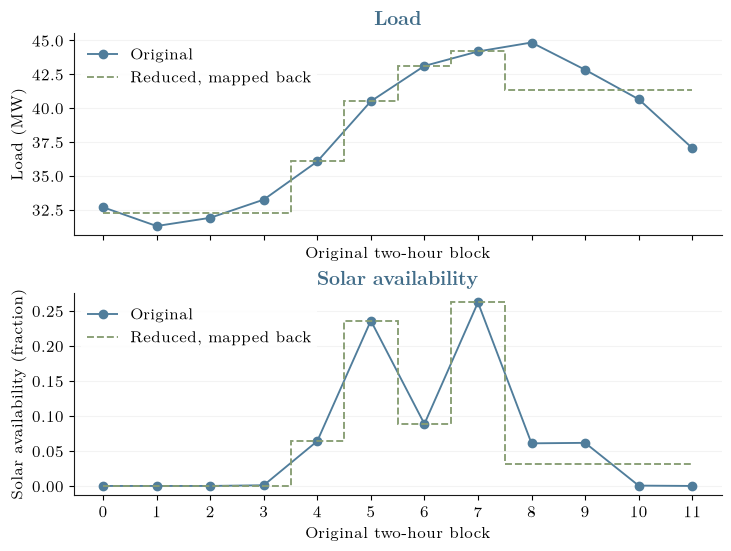

In [4]:
from gana.plotting import Series, column, line

reconstructed = np.empty_like(detailed)
for group, representative in zip(groups, reduced, strict=True):
    reconstructed[group] = representative

profiles = {"Original": detailed, "Reduced, mapped back": reconstructed}
profile_plots = []
positions = tuple(range(len(detailed)))
for field, (title, unit) in enumerate(
    [("Load", "MW"), ("Solar availability", "fraction")]
):
    series = [
        Series(
            x=positions,
            values=tuple(values[:, field]),
            coordinates=positions,
            domain=("source block",),
            key=(name,),
            label=name,
            unit=unit,
        )
        for name, values in profiles.items()
    ]
    profile_plots.append(
        (
            line(series[0], marker="o") + line(series[1], step="mid", linestyle="--")
        ).with_options(title=title, ylabel=f"{title} ({unit})")
    )
profile_plot = column(
    *profile_plots,
    sharex=True,
    fig_size=(7.2, 5.4),
    xlabel="Original two-hour block",
    ticks=list(positions),
)
profile_plot.show();